# Tutorial de CC408 Ciencia de Datos 2025
## Tutorial 5: Clusters

**Objetivo:**
Que se familiaricen con clusters (modelo no supervisado)

### Aprendizaje no supervisado
En gran parte del curso estudiamos modelos supervisados. Ahora veremos una herramienta no supervisada.

Cuando hablamos de **aprendizaje no supervisado** nos referimos a los casos en los que solo tenemos una cierta cantidad de _features_ o X, pero no contamos con una variable dependiente Y.

Por lo tanto, el objetivo no es predecir. El objetivo puede ser realizar un análisis explotatorio de los datos, ver las relaciones entre las X y ver si encontramos subgrupos (clusters) en los datos.

No contar con la variable de respuesta Y implica que tampoco podemos chequear si lo que estamos haciendo funciona bien o mal.
Por ende, perdemos la posibilidad de métodos de validación cruzada como lo veníamos haciendo.

En esta clase veremos ejemplos de Clusters.

### Método de Clustering 1: K-means

Clustering hace referencia a un conjunto de técnicas para encontrar subgrupos, o clusters, en los datos. Para ello, se busca partir a las observaciones en distintos grupos tal que se maximice la similitud entre las observaciones dentro de cada grupo, y se minimice la similitud entre estas y las observaciones de otros grupos.  

### K-means

En K-means clustering buscamos partir las observaciones en un número de clusters previamente especificado. Se determina el *K* deseado y el algoritmo asigna cada observación a a uno de los *K clusters* (sin superposición) buscando minimizar la variación intra-cluster. Para definir la variación intra-cluster la forma más usual es usar la distancia euclideana.

Usaremos el estimador [KMeans()](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) del módulo Cluster de Scikit Learn.


El procedimiento consiste en:
1. **Asignación inicial a los clusters**: Asigna aleatoriamente un número de 1 a K (*un grupo*) a cada una de las observaciones.
2. **Proceso iterativo**: Itera hasta que el cluster deja de modificarse:

  *  a) Para cada uno de los **K clusters**, se computa el centroide. El centroide del k-ésimo cluster es un vector con las *p* medias de las características (_features_) de las observaciones en el cluster.

  * b) Reasignar a cada observación al cluster cuyo centroide es más cercano (en términos de la distancia euclideana al centroide).

Ejemplo: **Progreso de K-means clustering con K=3**

0. Observaciones sin agrupar (Data).
1. Cada observación se asigna aleatoriamente a un cluster 1-K (Step 1).
2. Se computan los centroides de cada cluster (círculos más grandes). Al principio los centroides se superponen porque la asignación a los clusters fue elegida de forma aleatoria (Iteration 1, Step 2a).
3. Cada observación se asigna al centroide más cercano (Iteration 1, Step 2b).
4. Empieza una nueva iteración, se repite el paso 2, obteniendo nuevos centroides para cada clusters (Iteration 2, Step 2a).
5. Resultados luego de 10 iteraciones (Final Results)

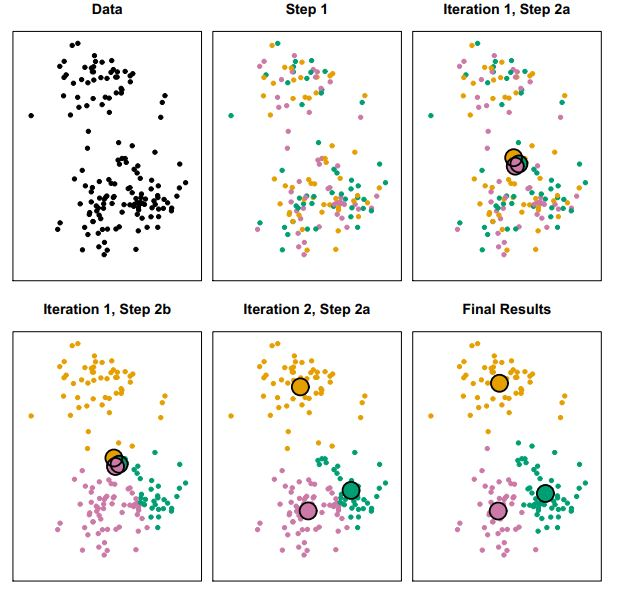

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering
from IPython.display import Image, display


Comencemos con un ejemplo simulado, en el que hay dos clusters en los datos: el primero, con 25 observaciones, tiene un desplazamiento de la media en relación a las 25 observaciones siguientes, que forman el segundo cluster.

In [ ]:
np.random.seed(0)
X = np.random.standard_normal((50,2))
#Observaciones random de un distribución Normal estándar con media=0 y sd=1
#50 observaciones, 2 columnas
X[:25,0] += 3
X[:25,1] -= 4
X

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(7,7))
ax.scatter(X[:,0], X[:,1])
ax.set_title("Observaciones")

Ahora realizamos K-means clustering con K=2. Para más información ver:  [KMeans()](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) del módulo Cluster de Scikit Learn.

Dentro de esta funcion podemos especificar:


*   `n_clusters`: número de clusters (*K* ).
*   `random_state`: semilla o *seed* para poder reproducir los resultados.
*   `n_init`: controla cuántas veces se ejecutará el algoritmo de K-means con diferentes semillas de centroides. Cada ejecución se realiza con una asignación aleatoria de centrodides diferente. El resultado final es aquel con menor **"inertia"**.



In [ ]:
kmeans2 = KMeans(n_clusters=2, random_state=10, init="random", n_init=20).fit(X)

Para ver a qué cluster fueron asignadas las 50 observaciones podemos usar el atributo labels_ del objeto kmeans


In [ ]:
kmeans2.labels_

In [ ]:
# Gráfico de las observaciones con las etiquetas correspondientes a cada cluster
fig, ax = plt.subplots(1, 1, figsize=(7,7))
ax.scatter(X[:,0], X[:,1], c=kmeans2.labels_)
ax.set_title("K-Means Clustering con K=2")

K-means clustering separó a las observaciones en dos grupos, las etiquetas son un resultado del procedimiento de clustering.
En este ejemplo es fácil gráficar porque solo tenemos dos dimensiones. Si hubiera más de dos variables podríamos realizar PCA y graficar los primeros dos vectores de componentes principales para representar a los clusters.

En este ejemplo sabíamos que eran dos clusters porque habíamos generado artificialmente los datos.
En otros casos reales, no sabemos de forma precisa el número de clusters ni si existen.
Podríamos haber hecho K-means Clustering con K=3 (`n_clusters=3`)


In [ ]:
kmeans3 = KMeans(n_clusters=3, random_state=10, init="random", n_init=20).fit(X)

# Gráfico
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(X[:,0], X[:,1], c=kmeans3.labels_)
ax.set_title("K-Means Clustering con K=3")


Notar que cuando K=3, el algoritmo parte los dos clusters iniciales

Otro parámetro de la función que definimos fue **n_init**.
Este parámetro indica la cantidad de veces que se corre el algoritmo con distintas asignaciones iniciales. Este argumento en el ejemplo toma valor 20 (el valor por default es 10). Cuando n_init > 1, K-means clustering se realiza usando multiples asignaciones aleatorias iniciales y la función KMeans() reporta solo los mejores resultados.
Como los grupos obtenidos dependen de esa asignación aleatoria inicial, la recomendación es correr el algoritmo varias veces con distintas asignaciones iniciales (n_init de 20 o 50)

Vamos a comparar los resultados usando `n_init=1`, `n_init=10`, y `n_init=20`.

(También es importante setear una semilla usando el argumento random_state de KMeans(). Así, el las asignaciones iniciales a clusters pueden ser replicadas y el resultado será reproducible.)


In [ ]:
kmeans3_i1 = KMeans(n_clusters=3, random_state=10, init="random", n_init=1).fit(X)
kmeans3_i10 = KMeans(n_clusters=3, random_state=10, init="random", n_init=10).fit(X)
kmeans3_i20 = KMeans(n_clusters=3, random_state=10, init="random", n_init=20).fit(X)
kmeans3_i1.inertia_, kmeans3_i10.inertia_, kmeans3_i20.inertia_

`kmeans.inertia_` es la suma de los cuadrados total dentro de un cluster. Inertia es una métrica que representa qué tan coherentes son las observaciones dentro de un cluster. Nos interesa tener el menor valor posible, **minimizar** esta medida.

In [ ]:
# Gráfico
fig, axes = plt.subplots(1, 2, figsize=(15, 6)) # 2 subplots uno al lado del otro
ax = axes[0]
ax.scatter(X[:,0], X[:,1], c=kmeans3_i1.labels_)
ax.set_title("K-Means Clustering con K=3 y n_init=1")
# capture suprime la visualización de la figura parcialmente terminada

ax = axes[1]
ax.scatter(X[:,0], X[:,1], c=kmeans3_i20.labels_)
ax.set_title("K-Means Clustering con K=3 y n_init=20")
plt.show()


En este sentido, el objetivo final de K-means es minimizar la distancia de todos los puntos a sus respectivos centroides. La *inertia* funciona como una forma de medir este error, cuanto menor sea, mejor es el clustering.

Debido a que K-means es un algoritmo iterativo que comienza con una asignación de centroides **aleatoria**, existe el riesgo de quedarnos con un **Mínimo Local** en lugar del **Mínimo Global**. Dependiendo de dónde caigan los centroides iniciales, el algoritmo puede encontrar un "pozo" del que ya no puede salir (las asignaciones dejan de cambiar). Este pozo, mínimo local, puede ser una buena agrupación, pero *no es la mejor posible*. Por ello, la norma es nunca correr K-means una sola vez.

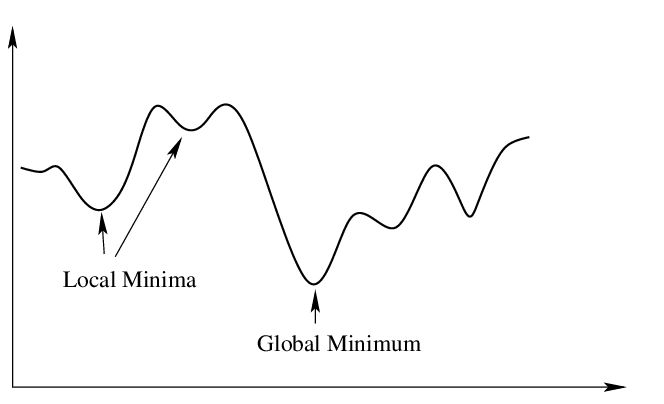

¿Como elegimos el K?

Como ya vimos, e algoritmo no sabe cuantos grupos K hay, esto es algo que nosotros tenemos que seleccionar de antemano. Una forma de elegirlo, similar a PCA, es mediante el **método del codo**.

Para ello graficamos la cantidad de clústeres (K, eje X) que vamos a probar vs. la dispersión promedio o *Inecia* (qué tan agrupados están los puntos respecto a sus centroides, eje Y). A medida que aumentamos K, la dispersión *siempre* va a disminuir. Por ejemplo, con 50 observaciones y K=50, la dispersión es 0 (cada punto es su propio cluster, y por ende, es igual a su centroide), pero el modelo es inútil.

Por ello, es necesario que busquemos el "balance" entre la simpleza del modelo (menor K) y que a su vez capture la mayor estructura posible de datos. En este sentido, "el codo" visual es el punto de inflexión en la curva, donde empezamos a encontrar *rendimientos decrecientes* (donde aumentar K apenas mejora el modelo)




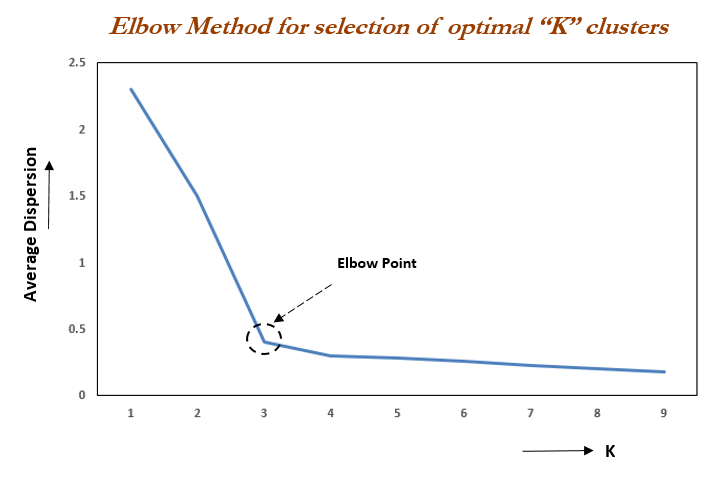

In [ ]:
#Creamos una lista vacía para guardar el error de cada modelo
inercias = []

#Probamos distintos valores de K (por ejemplo, de 1 a 10)
rango_k = range(1, 11)

for k in rango_k:
    #Configuramos el algoritmo
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)

    #Ajustamos el modelo a nuestros datos
    kmeans.fit(X)

    #Guardamos la inercia (la distancia promedio al centroide)
    inercias.append(kmeans.inertia_)

#Graficamos el Método del Codo
plt.figure(figsize=(8, 5))
plt.plot(rango_k, inercias, marker='o', linestyle='-', color='steelblue', linewidth=2)
plt.title('Método del Codo para seleccionar K óptimo', fontsize=14)
plt.xlabel('Cantidad de Clústeres (K)', fontsize=12)
plt.ylabel('Inercia (Dispersión interna)', fontsize=12)
plt.xticks(rango_k)
plt.grid(True, linestyle='--', alpha=0.7)

#Anotamos visualmente dónde está el codo (sabemos que generamos 2 en el dataset)
plt.annotate('Codo (Elbow)', xy=(2, inercias[1]), xytext=(5, inercias[1] + 20),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=12, fontweight='bold', color='darkred')

plt.tight_layout()
plt.show()

### Método de Clustering 2: Hierarchical Clustering

En el caso de Clustering jerárquico, a diferencia de K-medias, **no es necesario especificar previamente el número de clusters**. Obtendremos una representación visual de las observaciones a partir de un **dendrograma** que permite ver los subgrupos obtenidos para cada *número posible de clusters* (de 1 a n).

La forma más común de clustering jerárquico es _bottom-up_ o _agglomerative clustering_. Hace referencia a que el dendrograma se construye de abajo hacia arriba, comenzando por las hojas.

Usaremos [linkage()](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html#scipy.cluster.hierarchy.linkage) y [dendrogram()](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html) de Scipy.
También podríamos usar [AgglomerativeClustering()](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html) de Scikit Learn (módulo Cluster).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_iris

##### Ejemplo 1

In [ ]:
#Creamos datos
x1 = [4, 5, 10, 4, 3, 11, 14 , 6, 10, 12]
x2 = [21, 19, 24, 17, 16, 25, 24, 22, 21, 21]

data = list(zip(x1, x2)) # conjunto de datos bidimensional
data
#Tuplas con un par de observaciones cada una
#El 1° valor en la tupla es una observación de la lista x1 y el 2°, uno de la lista x2.

In [ ]:
fig, ax = plt.subplots(figsize=(6,6))
ax.scatter(x1, x2)
for i, txt in enumerate(range(len(x1))):
    ax.annotate(txt, (x1[i], x2[i]), textcoords="offset points", xytext=(0,10), ha='center')
ax.set_xlabel('x1')
ax.set_ylabel('x2')

In [ ]:
data_std = StandardScaler().fit_transform(data)
data_std

Ahora usamos linkage() de SciPy para realizar un agrupamiento jerárquico

Posibles opciones de funciones de enlace (Linkage):
- **Complete**: Mide la disimilitud máxima. Se calcula la distancia entre todos los puntos del cluster A y todos los puntos del B, y se define a la distancia entre estos como la distancia entre los puntos mas alejados entre si. Tiende a generar grupos muy compactos.

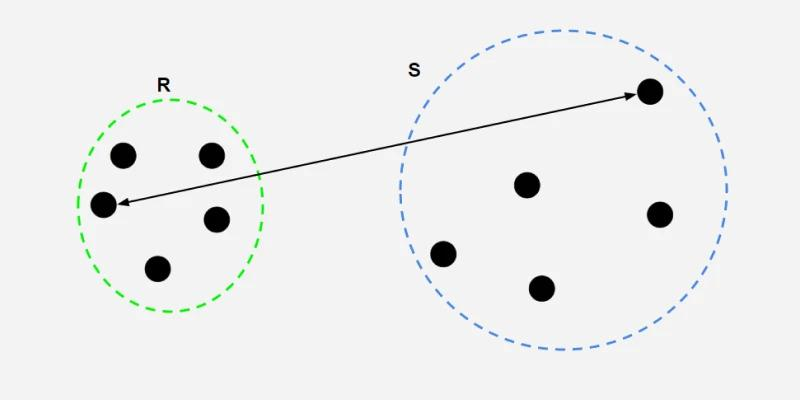

- **Single/Simple**:Mide la disimilituc mínima. Se calcula la distancia entre todos los puntos del cluster A y del B, y se define la distancia entre estos como la distancia más corta entre los puntos. Este método suele causar un efecto de encadenamiento (*chaining*), lo que crea clusters largos donde las observaciones individuales se van pegando una a una.   

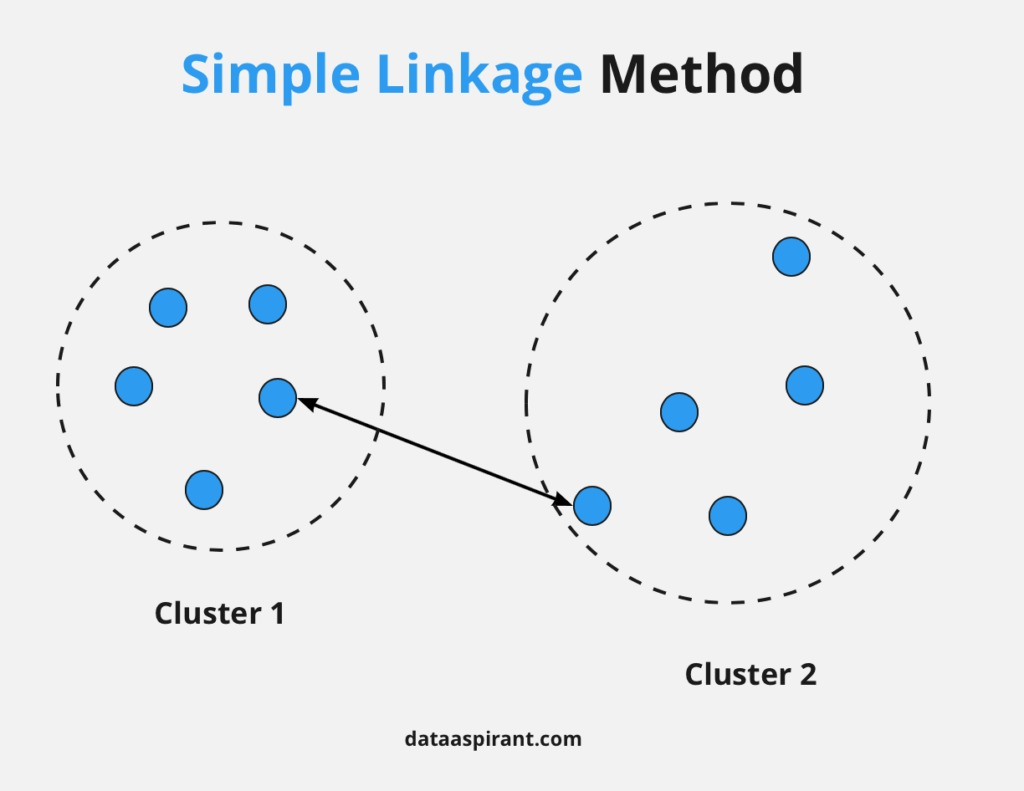

- **Average**: Mide la disimilitud media. Se calculala distancia entre todos los pares posibles de puntos y se toma el promedio de esas distancias.

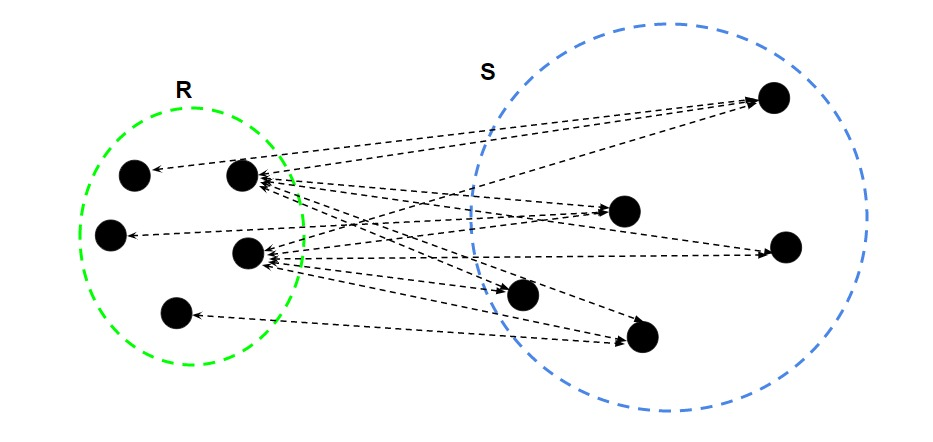

- **Centroid**: Mide la distancia entre el centroide (vector promedio) del cluster A y el centroide del cluster B. Este metodo puede causar *inversiones* en el dendrograma, lo que puede dificultar su interpretación visual.

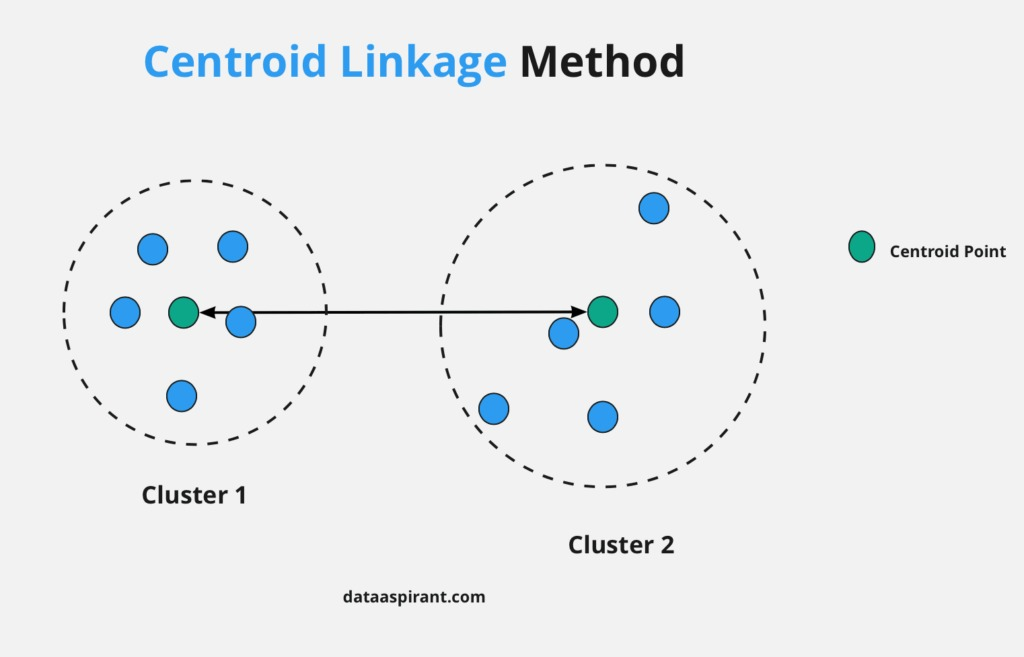

In [ ]:
linkage_data = linkage(data_std, metric='euclidean')
#Algunos parámetros que están determinados por default:
#metric='euclidean', method='simple'

#Graficamos
fig, ax = plt.subplots(figsize=(8,8))
dendrogram(linkage_data)
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6)) # 2 subplots uno al lado del otro
ax = axes[0]
ax.scatter(x1, x2)
for i, txt in enumerate(range(len(x1))):
    ax.annotate(txt, (x1[i], x2[i]), textcoords="offset points", xytext=(0,10), ha='center')
ax.set_xlabel('x1')
ax.set_ylabel('x2')

ax = axes[1]
dendrogram(linkage_data)
ax.set_title("Dendrogram")
plt.show()

Si  hacemos un corte horizontal en el dendograma podemos controlar cuántos clusters quedan.

In [ ]:
from scipy.cluster.hierarchy import cut_tree

# Para ver las etiquetas de clusters
# Si cortamos donde la altura es 4
labels_cut08 = cut_tree(linkage_data, height=0.8).reshape(-1)
print(labels_cut08)

fig, ax = plt.subplots(figsize=(12,6))
dendrogram(linkage_data)
ax.set_xlabel("Número de puntos en el nodo")
ax.axhline(0.8, c='red', linewidth=2) # línea horizontal en 4
plt.show()


In [ ]:
# Si queremos 3 clusters
labels_clust3 = cut_tree(linkage_data, n_clusters=3).reshape(-1)
print(labels_clust3)

# Ejemplo con datos reales: Subte Enero 2025

Ahora vamos a trabajar con datos reales, extrados de: https://data.buenosaires.gob.ar/dataset/subte-viajes-molinetes.

Esta base contiene los registros de molinetes de la red de Subte de Buenos Aires de enero de 2025 y, debido a su tamaño (más de 12.5 millones de viajes registrados), el gobierno lo disponibiliza dividido en dos grandes bloques:

*   `202501_PAX15min-ABC...csv`: Contiene la actividad de las Líneas A, B y C.
*   `202501_PAX15min-DEH...csv`: Contiene la actividad de las Líneas D, E y H.

Otra caracteristica de la base es que **no** tenemos el registro *por persona*, sino que cada fila contiene la información agregada temporalmente (15 minutos) de un *molinete específico*.  

#### Los archivos tienen las siguientes variables claves:
*   FECHA: El día exacto en el que ocurrió el registro (formato Día/Mes/Año, ej: 1/1/2025).

*   DESDE: La hora de inicio de la franja de medición (ej: 07:45:00).

*   HASTA: La hora en la que se cierra la franja de medición (ej: 08:00:00). Juntas, Desde y Hasta confirman que estamos viendo ventanas estrictas de 15 minutos.

*   LINEA: Identifica a qué línea de la red pertenece el registro (ej: LineaA, LineaB, LineaC).

*   ESTACION: El nombre de la estación de subte (ej: Carlos Gardel, Retiro, Constitucion).

*   MOLINETE: Es el código alfanumérico que identifica físicamente a la máquina exacta (ej: LineaB_Gardel_S_Turn02). Es importante destacar que una estación puede tener varios molinetes.

*   pax_pagos: Cantidad de pasajeros que abonaron la tarifa plana o estándar (el pasaje normal) en esa ventana de tiempo.

*   pax_pases_pagos: Cantidad de pasajeros que ingresaron usando un pase especial o abono comprado previamente.

*   pax_franq: Cantidad de pasajeros que pasaron utilizando una franquicia gratuita (como el Boleto Estudiantil).

*   pax_TOTAL: Es la suma exacta de las tres columnas anteriores (pagos + pases + franq). Representa la cantidad de personas que cruzaron el molinete (excluyendo, obviamente, a aquellas personas que lo saltan). Esta es la variable clave que vamos a usar en el modelo de K-Means, ya que para agrupar las estaciones por "ritmo urbano" no nos importa qué tarifa pagaron, sino a qué hora viajaron.

Como suele pasar con casi todos los datos libres, tienen un problema. Los archivos tienen un error de formato en su exportación original: cada fila está envuelta entera en comillas dobles (""), lo que rompe la lectura tradicional separada por comas o punto y coma. Tenemos que limpiar esto:

In [ ]:
import os
#os.chdir("/content/drive/MyDrive/Uni/Doctorado/Ciencia de Datos 2026/Tuto 5")
#os.chdir("/Users/rosarionamur/Desktop/Ciencia de Datos/Tut 5")
os.chdir("")

In [ ]:
import io
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import scipy.cluster.hierarchy as shc
from sklearn.cluster import AgglomerativeClustering

#Función para evadir las comillas
def cargar_subte_limpio(ruta):
    with open(ruta, 'r', encoding='utf-8-sig') as f:
        #Leemos el texto plano del archivo y eliminamos todas las comillas
        texto_limpio = f.read().replace('"', '')
    #Usamos io.StringIO para que Pandas lo lea como si fuera un archivo
    return pd.read_csv(io.StringIO(texto_limpio), sep=';', low_memory=False)

#Cargamos y unificación de las líneas A, B, C y D, E, H
df_abc = cargar_subte_limpio('202501_PAX15min-ABC-INCLUYEOTROMODOSDEPAGO.csv')
df_deh = cargar_subte_limpio('202501_PAX15min-DEH-INCLUYEOTROMODOSDEPAGO.csv')
df_total = pd.concat([df_abc, df_deh], ignore_index=True)

df_total.head()


In [ ]:
#Convertimos la fila DESDE a un formato de tiempo para trabajar mas facil
#Basicamente pasamos de '07:45:00' a 7
df_total['DESDE'] = pd.to_datetime(df_total['DESDE'], format='%H:%M:%S').dt.hour

#Construimos la matriz (Estaciones x Franjas Horarias)
matriz_estaciones = df_total.groupby(['ESTACION', 'DESDE'])['pax_TOTAL'].sum().unstack(fill_value=0) #Sumamos todos los pasajes

#Pasamos de cantidad total a porcentaje
matriz_perfiles = matriz_estaciones.div(matriz_estaciones.sum(axis=1), axis=0)

#Estandarizamos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(matriz_perfiles)

print(f"Matriz final: {X_scaled.shape[0]} estaciones y {X_scaled.shape[1]} franjas horarias.")

Ahora si, podemos ajustar el modelo por K-means

In [ ]:

#Ajustamos el modelo (asumiendo K=3)
kmeans = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

#Asignamos las etiquetas de cada cluster a la matriz original
df_resultados = matriz_perfiles.copy()
df_resultados['Cluster'] = clusters

#Calculamos el centroide
perfiles_promedio = df_resultados.groupby('Cluster').mean()

#Definimos cosas para el grafico
plt.figure(figsize=(14, 7))
colores = ['#e63946', '#1d3557', '#2a9d8f']
nombres_sugeridos = ['Perfil A (Mañana)', 'Perfil B (Tarde)', 'Perfil C (Constante)']

#Convertimos las horas a enteros puros
horas_limpias = perfiles_promedio.columns.astype(int)

for i in range(3):
    valores = perfiles_promedio.iloc[i]
    #Graficamos usando las horas limpias
    plt.plot(horas_limpias, valores, marker='o', linewidth=3, color=colores[i],
             label=f'Clúster {i}')

#Ajustes estéticos
plt.title('Dinámica de Pasajeros en Subte de CABA por Clúster', fontsize=16, fontweight='bold')
plt.xlabel('Hora del Día', fontsize=12)
plt.ylabel('Proporción del Tráfico Diario', fontsize=12)

#Definimos los ticks del eje X
plt.xticks(horas_limpias)

plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Grupos Descubiertos', fontsize=11)
plt.tight_layout()

plt.show()

#Veamos las estaciones que cayeron en cada grupo
print("\n--- Estaciones por Clúster ---")
for i in range(3):
    estaciones = df_resultados[df_resultados['Cluster'] == i].index.tolist()
    print(f"\nClúster {i} ({len(estaciones)} estaciones):")
    print(estaciones[:7], "...")

Si probamos con un jerarquico

In [ ]:
#Configuramos el grafico
plt.figure(figsize=(18, 8))
plt.title('Dendrograma: Agrupamiento Jerárquico de Estaciones', fontsize=16, fontweight='bold')
plt.xlabel('Estaciones de Subte', fontsize=12)
plt.ylabel('Distancia Euclidiana (Disimilitud)', fontsize=12)

#Aplicamos el modelo con "complete", pero podemos probar cambiarlo a "single" o "average"
matriz_enlace = shc.linkage(X_scaled, method='complete')

#Dibujamos el Dendrograma
dendrograma = shc.dendrogram(
    matriz_enlace,
    labels=matriz_perfiles.index.tolist(), #Ponemos los nombres reales de las estaciones
    leaf_rotation=90,                      #Rotamos los nombres 90 grados para que se lean
    leaf_font_size=9,                      #Tamaño de letra de las estaciones
    color_threshold=9                      #Altura donde queremos que cambien de color las ramas
)

#Trazamos una línea horizontal para mostrar dónde "cortamos" el árbol
plt.axhline(y=9, color='red', linestyle='--', linewidth=2, label='Línea de Corte')

plt.legend()
plt.tight_layout()
plt.show()

#Podemos aplicar y extraer las etiquetas
jerarquico = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='complete')
etiquetas_jerarquicas = jerarquico.fit_predict(X_scaled)

print("\nAsignación final (Primeras 5 estaciones):")
print(etiquetas_jerarquicas[:5])

# Metodos Extra

## K-Mode Clustering


A diferencia de **K-means**, que está pensado para variables numéricas y se basa en distancias euclídeas y promedios, el algoritmo **K-modes** es útil cuando trabajamos con datos **puramente categóricos** (ej.: color, marca, ciudad). En estos casos no tiene sentido calcular promedios, por lo que en lugar de usar medias como centroides utiliza **modas** (las categorías más frecuentes de cada columna en cada cluster) y la similitud se mide con la **distancia de Hamming**. En esta, si dos individuos tienen el mismo valor en una variable, la distancia es 0, mientras que si son dos diferentes, la distancia suma 1. Así, una observación se asigna al cluster con el cual comparte más categorías (es decir, donde sume menos diferencias). La interpretación de los resultados se hace leyendo los **perfiles típicos** de cada cluster: el vector de modas describe las características dominantes del grupo, y nos permite segmentar e identificar patrones comunes entre las observaciones.


In [ ]:
!pip install kmodes

In [ ]:
from kmodes.kmodes import KModes

Comenzamos creando una base de datos que tenga solo categorias, como una tabla de pedidos:

In [ ]:
df = pd.DataFrame({
    "Color":   ["Rojo","Azul","Verde","Rojo","Azul","Verde","Rojo","Azul","Rojo","Verde"],
    "Marca":   ["A","B","A","A","C","B","C","B","A","C"],
    "Talle":   ["S","M","L","M","S","M","L","S","M","L"],
    "Ciudad":  ["CABA","CABA","LaPlata","Córdoba","CABA","Rosario","Córdoba","Rosario","LaPlata","CABA"]
})

#Nos quedamos solo con las celdas
X_cat = df.astype(str).values

#Aplicamos el modelo
km = KModes(n_clusters=3, init="Huang", n_init=5, random_state=42)
labels = km.fit_predict(X_cat)
df["cluster"] = labels

In [ ]:
centroides = pd.DataFrame(km.cluster_centroids_, columns=df.columns[:-1])
print("Centroides (modas) por cluster:")
display(centroides)

In [ ]:
print("\nAsignaciones de cluster:")
display(df)


In [ ]:
print("\nPerfil de clusters (frecuencias por categoría):")
for col in df.columns[:-1]:
    print(f"\nColumna: {col}")
    display(pd.crosstab(df[col], df["cluster"], normalize="columns").round(2))


## K-Prototypes

Para los casos en los cuales el dataset tiene variables númericas y categóricas, por lo que no podemos utilizar K-means o K-modes, existe una solución híbrida: K-prototypes.

Para ello, el centroide de cada cluster tiene un porción numérica (se calcula usando la media) y una porción categórica (que se calcula usando la moda, como K-modes). En este sentido, la distancia se calcula con la métrica combinada:

$$D = D_{num} + \gamma \cdot D_{cat}$$

Donde $D_{num}$ es la distancia euclidiana clásica, $D_{cat}$ es la cantidad de diferencias en las categorías y $\gamma$ es un parámetro elegido por nosotros que le da peso a las diferencias categóricas (si $\gamma$ es alto, le da importancia a las categorias, mientras que si es cercano a 0, las ignora y se centra en los números).

In [ ]:
from kmodes.kprototypes import KPrototypes #Esta en la libreria kmodes

#Creamos un dataset mixto de ejemplo (clientes)
datos = pd.DataFrame({
    'Edad': [25, 34, 22, 45, 33, 23],                                 # Numérica
    'Ingresos': [50000, 70000, 48000, 120000, 68000, 52000],          # Numérica
    'Estado_Civil': ['Soltero', 'Casado', 'Soltero', 'Casado', 'Casado', 'Soltero'], # Categórica
    'Ciudad': ['CABA', 'Córdoba', 'CABA', 'Rosario', 'Córdoba', 'CABA']              # Categórica
})

#Identificamos los índices de las columnas categóricas: 'Estado_Civil' es 2 y 'Ciudad' es 3.
columnas_categoricas = [2, 3]

#Instanciamos el modelo
#init='Cao' es un método de inicialización optimizado específicamente para datos mixtos
kproto = KPrototypes(n_clusters=2, init='Cao', n_init=5, random_state=42)

#La funcion automaticamente calcula el gamma a partir de las variables numericas
# del dataset. Si lo quisieramos cambiar, podemos usar, por ejemplo:

#kproto = KPrototypes(n_clusters=2, init='Cao', n_init=5, gamma=0.5, random_state=42)

#Ajustamos el modelo (en categorical tenemos que indicar cuales son las posiciones
# de variable categoricas)
clusters = kproto.fit_predict(datos, categorical=columnas_categoricas)

#Vemos los centroides:
print("Centroides: \n", kproto.cluster_centroids_, "\n")


#Anexamos los resultados al dataframe original para visualizarlos
datos['Cluster_Asignado'] = clusters

print(datos)

# Ejercicios para prácticar

En la carpeta compartida pueden encontrar el archivo `Mall_Customers.csv` que tiene características de clientes de un mall. Utilizando `K-means`, agrupe los datos de acuerdo a la cantidad de grupos que le parezca razonable. ¿Puede decir algo de los agrupamientos?

In [ ]:
df = pd.read_csv("Mall_Customers.csv")
df